In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
os.makedirs("../../reports/figures", exist_ok=True)

df = pd.read_csv("../../data/raw/upi_transactions_2024_raw.csv")
df = df.rename(columns={"transaction id": "transaction_id",
                        "transaction type": "transaction_type",
                        "amount (INR)": "amount_inr"})
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["month"] = df["timestamp"].dt.month
df.head()

,transaction_id,timestamp,transaction_type,merchant_category,amount_inr,transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend,month
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0,10
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0,4
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0,4
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0,1


fraud_flag
0    249520
1       480
Name: count, dtype: int64
Fraud %: 0.192


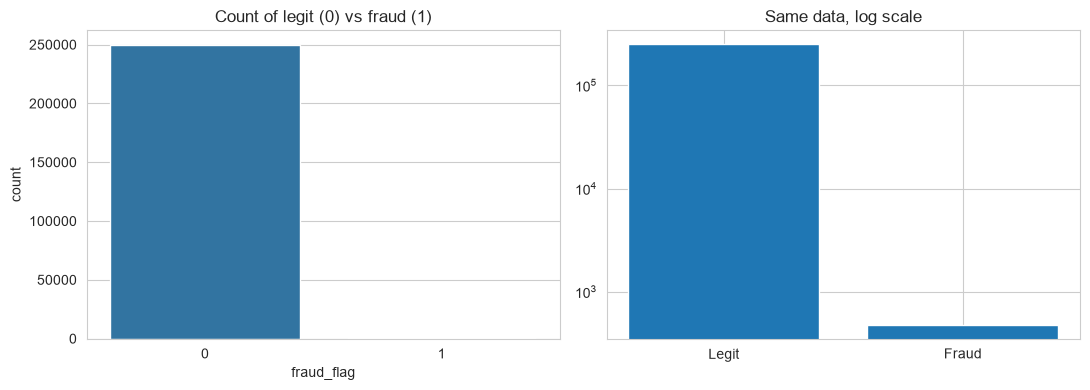

In [2]:
counts = df["fraud_flag"].value_counts()
print(counts)
print("Fraud %:", round(df["fraud_flag"].mean() * 100, 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="fraud_flag", data=df, ax=axes[0])
axes[0].set_title("Count of legit (0) vs fraud (1)")
axes[1].bar(["Legit", "Fraud"], counts.values)
axes[1].set_yscale("log")
axes[1].set_title("Same data, log scale")
plt.tight_layout()
plt.savefig("../../reports/figures/01_class_imbalance.png", dpi=120)
plt.show()

**Observation:** Only 480 of 250,000 transactions (0.19%) are fraud. In the normal
chart the fraud bar is invisible. A model that always says "not fraud" would be
99.8% accurate, so **accuracy is useless here**. Use precision, recall, F1 and PR-AUC.

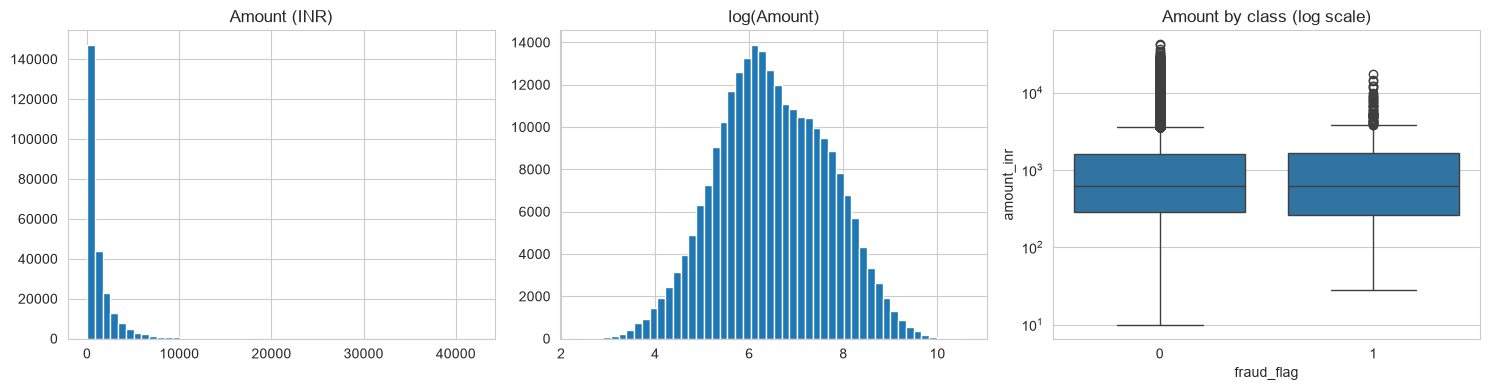

,count,mean,std,min,25%,50%,75%,max
fraud_flag,,,,,,,,
0,249520.0,1311.0,1847.0,10.0,288.0,629.0,1596.0,42099.0
1,480.0,1499.0,2241.0,28.0,260.0,618.0,1674.0,17718.0


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["amount_inr"], bins=50)
axes[0].set_title("Amount (INR)")
axes[1].hist(np.log1p(df["amount_inr"]), bins=50)
axes[1].set_title("log(Amount)")
sns.boxplot(x="fraud_flag", y="amount_inr", data=df, ax=axes[2])
axes[2].set_yscale("log")
axes[2].set_title("Amount by class (log scale)")
plt.tight_layout()
plt.savefig("../../reports/figures/02_amount_distribution.png", dpi=120)
plt.show()

df.groupby("fraud_flag")["amount_inr"].describe().round(0)

**Observation:** Amounts are heavily right-skewed (many small payments, few very big
ones). After the log transform it looks much more normal. Fraud and legit amounts are
almost the same (median Rs 618 vs Rs 629). Fraud has a slightly higher mean
(Rs 1,499 vs Rs 1,311) because of a few big values.

In [4]:
def fraud_rate_plot(column, filename, rotate=0):
    table = df.groupby(column)["fraud_flag"].agg(["mean", "sum", "count"])
    table["fraud_rate_%"] = table["mean"] * 100
    table = table.sort_values("fraud_rate_%", ascending=False)

    plt.figure(figsize=(8, 4))
    sns.barplot(x=table.index, y=table["fraud_rate_%"])
    plt.axhline(df["fraud_flag"].mean() * 100, color="red",
                linestyle="--", label="overall rate")
    plt.title("Fraud rate (%) by " + column)
    plt.xticks(rotation=rotate)
    plt.legend()
    plt.tight_layout()
    plt.savefig("../../reports/figures/" + filename, dpi=120)
    plt.show()
    return table[["sum", "count", "fraud_rate_%"]].round(3)

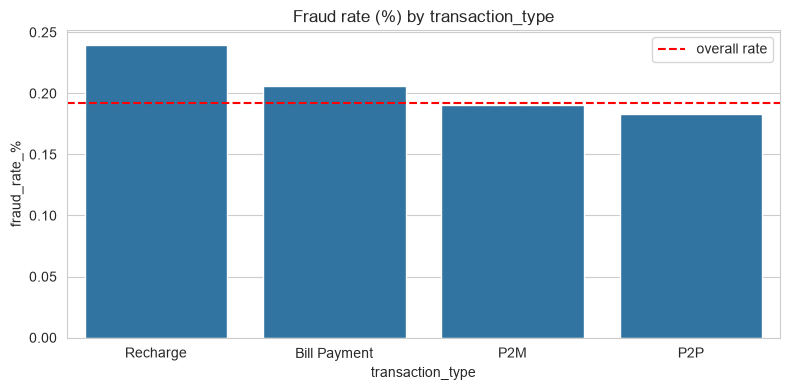

,sum,count,fraud_rate_%
transaction_type,,,
Recharge,30,12527,0.239
Bill Payment,77,37368,0.206
P2M,167,87660,0.191
P2P,206,112445,0.183


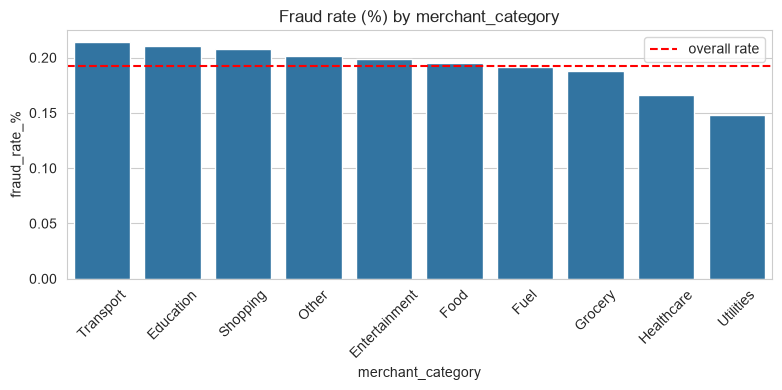

,sum,count,fraud_rate_%
merchant_category,,,
Transport,43,20105,0.214
Education,16,7598,0.211
Shopping,62,29872,0.208
Other,50,24828,0.201
Entertainment,40,20103,0.199
Food,73,37464,0.195
Fuel,48,25063,0.192
Grocery,94,49966,0.188
Healthcare,21,12663,0.166


In [5]:
display(fraud_rate_plot("transaction_type", "03_fraud_by_type.png"))
display(fraud_rate_plot("merchant_category", "04_fraud_by_category.png", 45))

**Observation:** Fraud rates are all close to the red line (about 0.19%). Recharge is
a bit higher (0.24%) and P2P a bit lower (0.18%), but the differences are tiny and
based on few fraud cases. Transaction type and merchant category do not look useful.

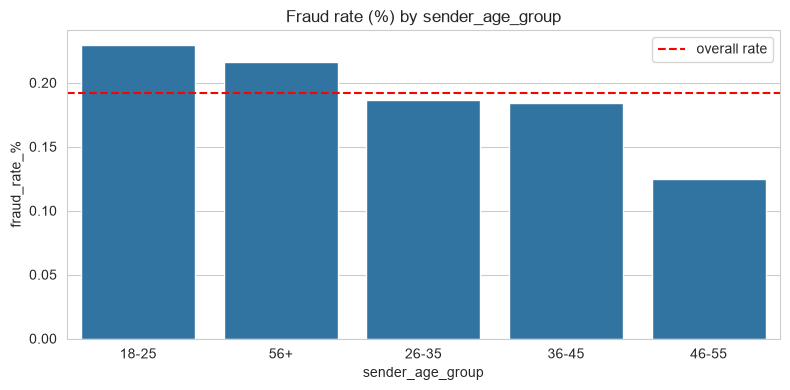

,sum,count,fraud_rate_%
sender_age_group,,,
18-25,143,62345,0.229
56+,27,12509,0.216
26-35,163,87432,0.186
36-45,116,62873,0.184
46-55,31,24841,0.125


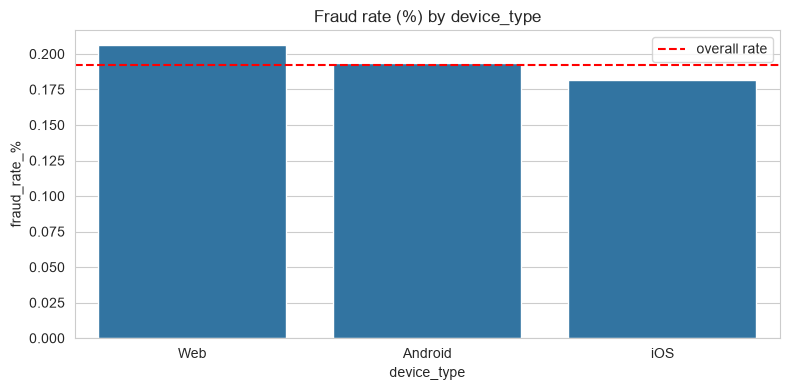

,sum,count,fraud_rate_%
device_type,,,
Web,26,12610,0.206
Android,364,187777,0.194
iOS,90,49613,0.181


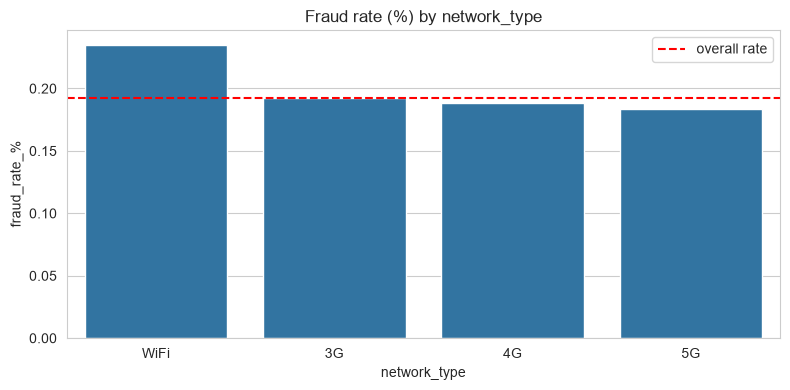

,sum,count,fraud_rate_%
network_type,,,
WiFi,59,25134,0.235
3G,24,12471,0.192
4G,282,149813,0.188
5G,115,62582,0.184


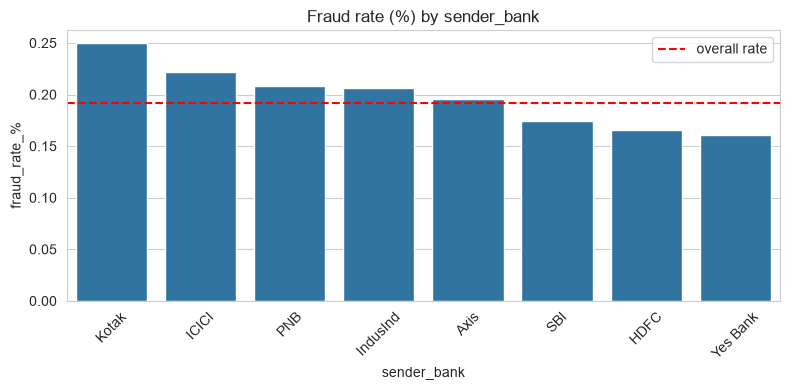

,sum,count,fraud_rate_%
sender_bank,,,
Kotak,50,20032,0.250
ICICI,66,29769,0.222
PNB,52,24946,0.208
IndusInd,52,25173,0.207
Axis,49,25042,0.196
SBI,109,62693,0.174
HDFC,62,37485,0.165
Yes Bank,40,24860,0.161


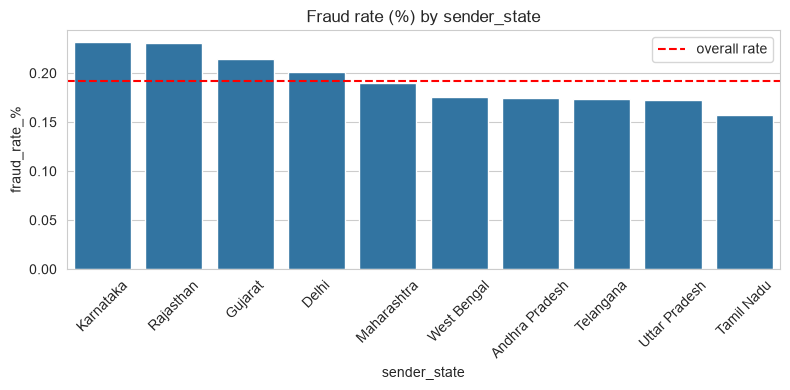

,sum,count,fraud_rate_%
sender_state,,,
Karnataka,69,29756,0.232
Rajasthan,46,19981,0.230
Gujarat,43,20061,0.214
Delhi,50,24870,0.201
Maharashtra,71,37427,0.190
West Bengal,35,19972,0.175
Andhra Pradesh,35,20006,0.175
Telangana,39,22435,0.174
Uttar Pradesh,52,30125,0.173


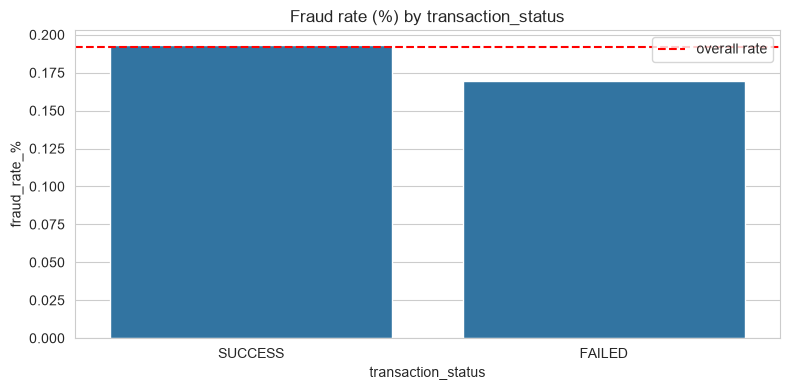

,sum,count,fraud_rate_%
transaction_status,,,
SUCCESS,459,237624,0.193
FAILED,21,12376,0.170


In [6]:
display(fraud_rate_plot("sender_age_group", "05_fraud_by_age.png"))
display(fraud_rate_plot("device_type", "06_fraud_by_device.png"))
display(fraud_rate_plot("network_type", "07_fraud_by_network.png"))
display(fraud_rate_plot("sender_bank", "08_fraud_by_sender_bank.png", 45))
display(fraud_rate_plot("sender_state", "09_fraud_by_state.png", 45))
display(fraud_rate_plot("transaction_status", "10_fraud_by_status.png"))

**Observation:** The age group 18-25 has the highest fraud rate (0.23%) and 46-55
the lowest (0.12%). Banks, states, devices and networks all stay near 0.15-0.25%.
Some bars look different only because each group has just 20-100 fraud cases,
so this can be random noise (see the p-values at the end).

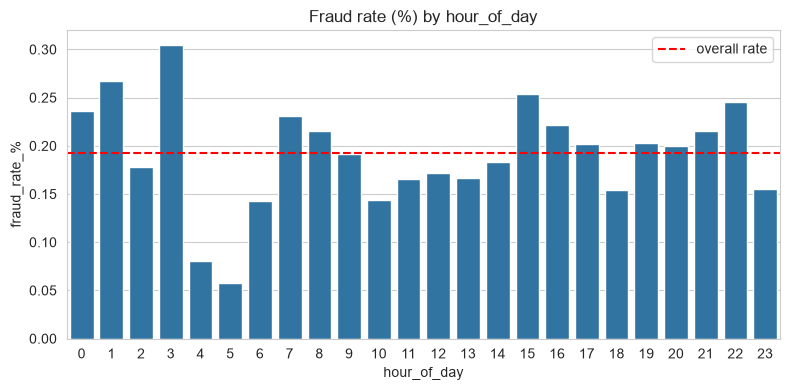

,sum,count,fraud_rate_%
hour_of_day,,,
3,4,1314,0.304
1,6,2244,0.267
15,32,12624,0.253
22,23,9364,0.246
0,8,3388,0.236


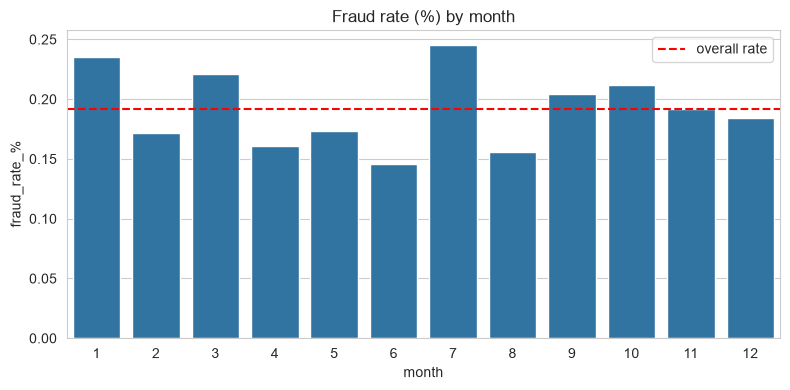

,sum,count,fraud_rate_%
month,,,
7,52,21207,0.245
1,50,21221,0.236
3,47,21234,0.221
10,45,21252,0.212
9,42,20597,0.204


In [7]:
display(fraud_rate_plot("hour_of_day", "11_fraud_by_hour.png").head())
display(fraud_rate_plot("month", "12_fraud_by_month.png").head())

**Observation:** The hour chart jumps up and down (0.06% to 0.30%) with no clear
night-time pattern. Night (hours 0-5) fraud is 0.198% vs 0.192% for the rest of the
day, which is basically the same. The same is true for months.

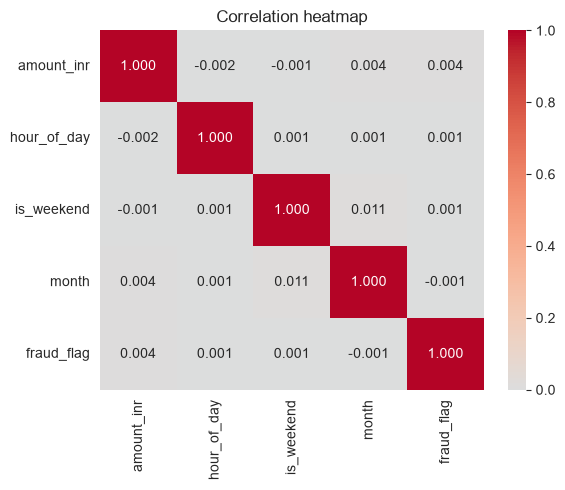

In [9]:
num_cols = ["amount_inr", "hour_of_day", "is_weekend", "month", "fraud_flag"]

plt.figure(figsize=(6, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".3f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("../../reports/figures/13_correlation_heatmap.png", dpi=120)
plt.show()

**Observation:** All correlations are near 0 (fraud vs amount is 0.004). No number
column is linearly related to fraud, and the features are independent of each other.

In [10]:
Q1 = df["amount_inr"].quantile(0.25)
Q3 = df["amount_inr"].quantile(0.75)
upper_limit = Q3 + 1.5 * (Q3 - Q1)
df["is_outlier"] = df["amount_inr"] > upper_limit

print("Upper limit:", upper_limit)
print("Number of outliers:", df["is_outlier"].sum())
print()
print("Fraud rate (%) for normal vs outlier amounts:")
print(df.groupby("is_outlier")["fraud_flag"].mean() * 100)
print()
print("Average amount by merchant category:")
print(df.groupby("merchant_category")["amount_inr"].mean().round(0).sort_values())
print()
print("Top 5 biggest transactions:")
display(df.sort_values("amount_inr", ascending=False).head(5)
        [["transaction_id", "amount_inr", "transaction_type", "merchant_category", "fraud_flag"]])

Upper limit: 3558.0
Number of outliers: 21171

Fraud rate (%) for normal vs outlier amounts:
is_outlier
False    0.184417
True     0.273960
Name: fraud_flag, dtype: float64

Average amount by merchant category:
merchant_category
Transport         308.0
Entertainment     413.0
Food              532.0
Healthcare        543.0
Other             849.0
Grocery          1166.0
Fuel             1555.0
Utilities        2361.0
Shopping         2573.0
Education        5094.0
Name: amount_inr, dtype: float64

Top 5 biggest transactions:


,transaction_id,amount_inr,transaction_type,merchant_category,fraud_flag
144868,TXN0000144869,42099,P2P,Education,0
233820,TXN0000233821,41210,Bill Payment,Education,0
195366,TXN0000195367,37263,Recharge,Education,0
72465,TXN0000072466,34304,P2P,Education,0
25258,TXN0000025259,33061,P2P,Education,0


**Observation:** About 21,000 amounts (8.5%) are above Rs 3,558. These are not errors.
Education (average Rs 5,094), Shopping and Utilities simply have bigger payments, so
we should **keep** the outliers. Fraud is slightly more common among them (0.27% vs
0.18%), which is the only amount-related signal we found.

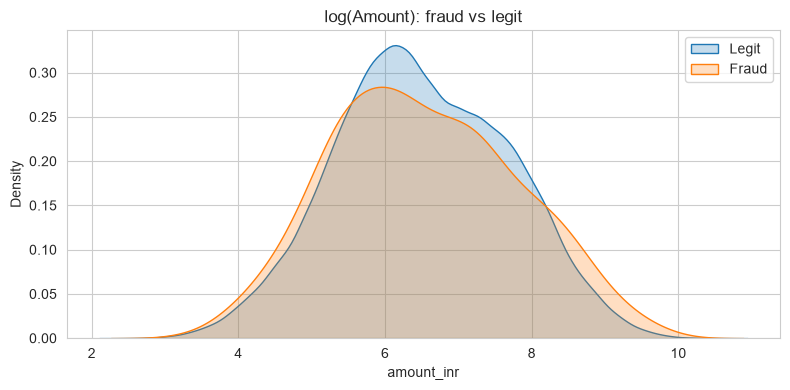

transaction_type p-value = 0.508
merchant_category p-value = 0.913
sender_age_group p-value = 0.026
device_type p-value = 0.796
network_type p-value = 0.435
sender_bank p-value = 0.238
sender_state p-value = 0.558


In [11]:
plt.figure(figsize=(8, 4))
sns.kdeplot(np.log1p(df[df.fraud_flag == 0]["amount_inr"]), label="Legit", fill=True)
sns.kdeplot(np.log1p(df[df.fraud_flag == 1]["amount_inr"]), label="Fraud", fill=True)
plt.title("log(Amount): fraud vs legit")
plt.legend()
plt.tight_layout()
plt.savefig("../../reports/figures/14_amount_fraud_vs_legit.png", dpi=120)
plt.show()

# Chi-square test: is fraud really connected to this column?
# p-value below 0.05 means "probably a real connection"
for col in ["transaction_type", "merchant_category", "sender_age_group",
            "device_type", "network_type", "sender_bank", "sender_state"]:
    p = stats.chi2_contingency(pd.crosstab(df[col], df["fraud_flag"]))[1]
    print(col, "p-value =", round(p, 3))

## Summary of findings
- **Class imbalance is the biggest problem:** 0.19% fraud (480 cases).
- **Features show very weak signal.** Chi-square p-values are above 0.05 for type,
  category, device, network, bank and state. Only `sender_age_group` is below 0.05
  (p = 0.026), and with 7 tests this could be luck.
- Fraud and legit amounts have almost the same distribution.
  Amounts above Rs 3,558 have slightly more fraud (0.27% vs 0.18%).
- Time features (hour, weekday, month) show no pattern.
- Correlations are all about 0.

## Potential issues
1. Very few fraud rows, so the model can easily overfit or learn noise.
2. The data looks synthetic, as features are nearly independent of the target.
   Expect low model scores, and be suspicious of any very high score (data leakage).
3. No user ID or device ID, so we cannot build features such as "many payments from
   one user in 10 minutes".
4. `transaction id`, `timestamp` carry no useful signal.